In [1]:
from google.colab import files
uploaded = files.upload()

Saving DailyDelhiClimateTest.csv to DailyDelhiClimateTest (1).csv
Saving DailyDelhiClimateTrain.csv to DailyDelhiClimateTrain (1).csv


In [2]:
import pandas as pd
import numpy as np

# Load the training dataset
file_name = "DailyDelhiClimateTrain.csv"
df = pd.read_csv(file_name)

# Convert date to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Display basic information
print("Dataset shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1462, 5)

First 5 records:


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1462 non-null   datetime64[ns]
 1   meantemp      1462 non-null   float64       
 2   humidity      1462 non-null   float64       
 3   wind_speed    1462 non-null   float64       
 4   meanpressure  1462 non-null   float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 57.2 KB

Missing values:
date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


In [3]:
# Sort records chronologically
df = df.dropna(subset=["date"])
df = df.sort_values("date")

# Remove duplicate dates, keeping the first record
df = df.drop_duplicates(subset=["date"], keep="first")

# Weather feature columns
weather_features = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

# Convert weather columns to numeric values
for col in weather_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace infinite values with NaN
df[weather_features] = df[weather_features].replace(
    [np.inf, -np.inf], np.nan
)

# Set date as index for time-based interpolation
df = df.set_index("date")

# Interpolate missing values using time
df[weather_features] = df[weather_features].interpolate(
    method="time",
    limit_area="inside"
)

# Fill any remaining missing values at the boundaries
df[weather_features] = df[weather_features].ffill().bfill()

# Reset index
df = df.reset_index()

# Check cleaned dataset
print("Shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df[weather_features].isnull().sum())

print("\nDuplicate dates:", df["date"].duplicated().sum())

display(df.head())

Shape after cleaning: (1462, 5)

Missing values after cleaning:
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

Duplicate dates: 0


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [4]:
from sklearn.preprocessing import MinMaxScaler

# Create a scaler
scaler = MinMaxScaler()

# Normalize the weather features
df_normalized = df.copy()

df_normalized[weather_features] = scaler.fit_transform(
    df[weather_features]
)

print("Normalized weather features:")
display(df_normalized.head())

print("\nMinimum values after normalization:")
print(df_normalized[weather_features].min())

print("\nMaximum values after normalization:")
print(df_normalized[weather_features].max())

Normalized weather features:


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,0.122271,0.820957,0.000000,0.132603
1,2013-01-02,0.042795,0.907591,0.070583,0.132881
2,2013-01-03,0.035662,0.849835,0.109743,0.132994
3,2013-01-04,0.081514,0.668867,0.029212,0.132799
4,2013-01-05,0.000000,0.847910,0.087636,0.132712



Minimum values after normalization:
meantemp        0.0
humidity        0.0
wind_speed      0.0
meanpressure    0.0
dtype: float64

Maximum values after normalization:
meantemp        1.0
humidity        1.0
wind_speed      1.0
meanpressure    1.0
dtype: float64


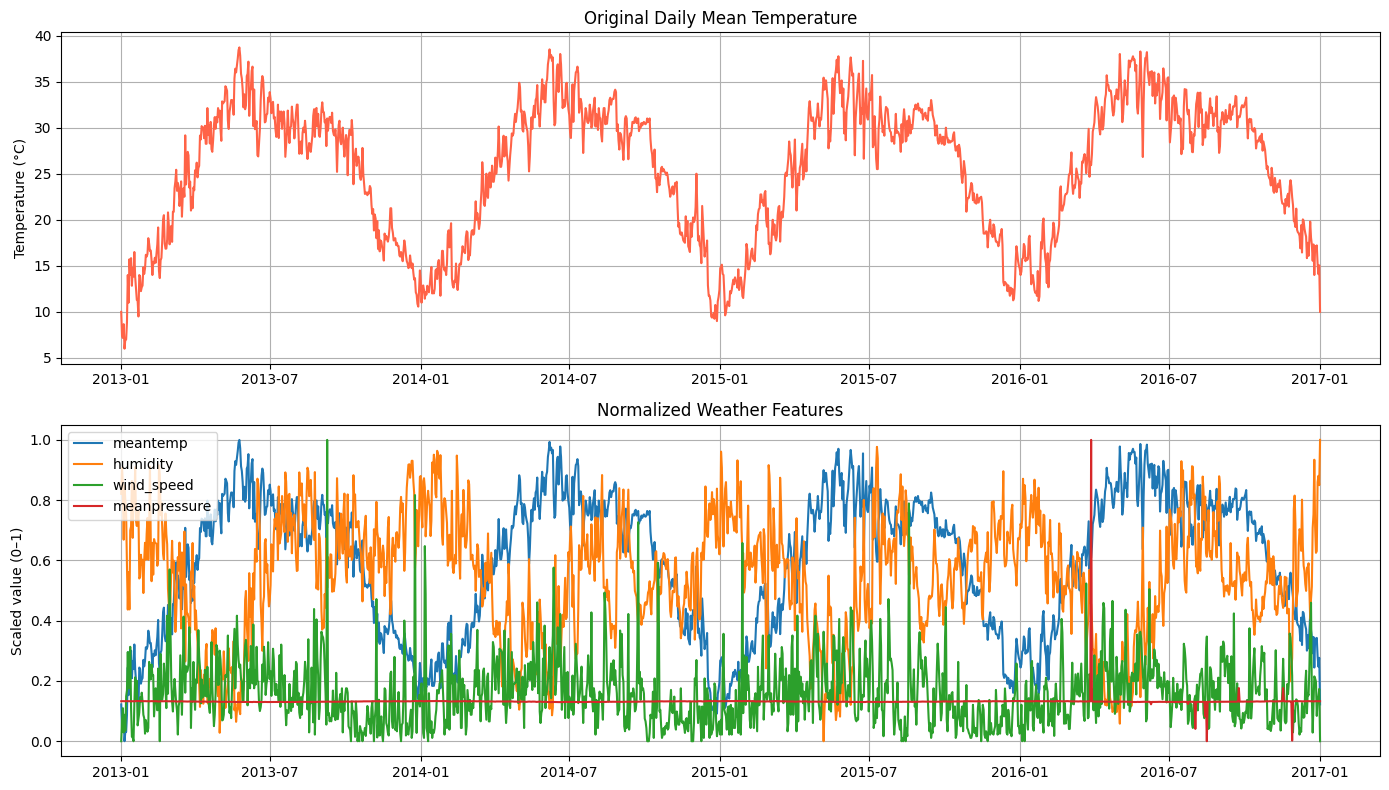

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Original mean temperature
axes[0].plot(df["date"], df["meantemp"], color="tomato")
axes[0].set_title("Original Daily Mean Temperature")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(True)

# Normalized weather features
for col in weather_features:
    axes[1].plot(
        df_normalized["date"],
        df_normalized[col],
        label=col
    )

axes[1].set_title("Normalized Weather Features")
axes[1].set_ylabel("Scaled value (0–1)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [6]:
# Save both versions
df.to_csv("cleaned_weather_data.csv", index=False)
df_normalized.to_csv("normalized_weather_data.csv", index=False)

print("Files saved successfully!")

# Download normalized data
files.download("normalized_weather_data.csv")

Files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
# Input features
features = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

# Target variable
target = "meantemp"

X_data = df_normalized[features].values
y_data = df_normalized[target].values

print("Input features:", features)
print("Target variable:", target)
print("Input data shape:", X_data.shape)
print("Target data shape:", y_data.shape)

Input features: ['meantemp', 'humidity', 'wind_speed', 'meanpressure']
Target variable: meantemp
Input data shape: (1462, 4)
Target data shape: (1462,)


In [8]:
# Number of historical days used for prediction
sequence_length = 7

X_sequences = []
y_sequences = []
target_dates = []

for i in range(sequence_length, len(df_normalized)):
    # Previous 7 days of all weather features
    X_sequences.append(X_data[i-sequence_length:i])

    # Next day's mean temperature
    y_sequences.append(y_data[i])

    # Date corresponding to the prediction target
    target_dates.append(df_normalized["date"].iloc[i])

# Convert lists into NumPy arrays
X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)
target_dates = np.array(target_dates)

print("Sequence generation completed!")
print("X shape:", X_sequences.shape)
print("y shape:", y_sequences.shape)
print("Target dates shape:", target_dates.shape)

Sequence generation completed!
X shape: (1455, 7, 4)
y shape: (1455,)
Target dates shape: (1455,)


In [9]:
# Display the first input sequence
first_sequence = pd.DataFrame(
    X_sequences[0],
    columns=features
)

print("First 7-day historical sequence:")
display(first_sequence)

print("Target date:", target_dates[0])
print("Actual normalized target temperature:", y_sequences[0])

First 7-day historical sequence:


,meantemp,humidity,wind_speed,meanpressure
0,0.122271,0.820957,0.000000,0.132603
1,0.042795,0.907591,0.070583,0.132881
2,0.035662,0.849835,0.109743,0.132994
3,0.081514,0.668867,0.029212,0.132799
4,0.000000,0.847910,0.087636,0.132712
5,0.030568,0.801320,0.035054,0.132907
6,0.030568,0.752805,0.149218,0.133167


Target date: 2013-01-08 00:00:00
Actual normalized target temperature: 0.08733624454148473


In [10]:
np.save("X_sequences.npy", X_sequences)
np.save("y_sequences.npy", y_sequences)
np.save("target_dates.npy", target_dates)

print("Saved successfully:")
print("X_sequences.npy")
print("y_sequences.npy")
print("target_dates.npy")

Saved successfully:
X_sequences.npy
y_sequences.npy
target_dates.npy


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the cleaned dataset if it is not already in memory
if "df" not in globals() or "date" not in df.columns:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv("cleaned_weather_data.csv")

# Prepare data
df = df.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates("date").reset_index(drop=True)

features = ["meantemp", "humidity", "wind_speed", "meanpressure"]
target = "meantemp"
sequence_length = 7

# Chronological 80/20 split
split_index = int(len(df) * 0.80)

# Fit scaler on training period only
scaler = MinMaxScaler()
scaler.fit(df.loc[:split_index - 1, features])

# Transform the full series using training-fitted scaling
scaled_data = scaler.transform(df[features])

print("Total daily records:", len(df))
print("Training period records:", split_index)
print("Testing period records:", len(df) - split_index)
print("Training ends:", df["date"].iloc[split_index - 1].date())
print("Testing begins:", df["date"].iloc[split_index].date())

Total daily records: 1462
Training period records: 1169
Testing period records: 293
Training ends: 2016-03-14
Testing begins: 2016-03-15


In [12]:
X, y, target_indices = [], [], []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i, :])
    y.append(scaled_data[i, 0])  # meantemp is the first feature
    target_indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_indices = np.array(target_indices)

# Split by target date, preserving chronological order
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1162, 7, 4)
y_train: (1162,)
X_test: (293, 7, 4)
y_test: (293,)


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(sequence_length, len(features))),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.1769 - mae: 0.3495 - val_loss: 0.0314 - val_mae: 0.1462
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0268 - mae: 0.1338 - val_loss: 0.0039 - val_mae: 0.0478
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0112 - mae: 0.0827 - val_loss: 0.0037 - val_mae: 0.0459
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0119 - mae: 0.0860 - val_loss: 0.0036 - val_mae: 0.0454
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0099 - mae: 0.0783 - val_loss: 0.0036 - val_mae: 0.0461
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0096 - mae: 0.0767 - val_loss: 0.0035 - val_mae: 0.0449
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0097 - mae: 0.0777 - val_loss: 0.0036 - val_mae: 0.0465
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0092 - mae: 0.0756 - val_loss: 0.0034 - val_mae: 0.0443
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - lo

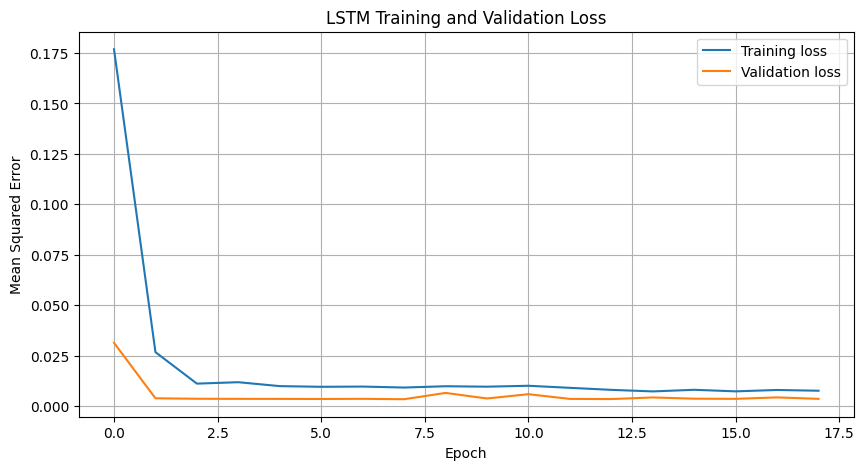

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
from sklearn.metrics import r2_score

# Predict normalized temperatures
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized temperatures back to Celsius
temp_min = scaler.data_min_[0]
temp_max = scaler.data_max_[0]

y_test_celsius = y_test * (temp_max - temp_min) + temp_min
y_pred_celsius = (
    y_pred_scaled.ravel() * (temp_max - temp_min) + temp_min
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_celsius, y_pred_celsius)
rmse = np.sqrt(mean_squared_error(y_test_celsius, y_pred_celsius))
r2 = r2_score(y_test_celsius, y_pred_celsius)

print("LSTM Temperature Forecasting Results")
print("------------------------------------")
print(f"MAE  : {mae:.3f} °C")
print(f"RMSE : {rmse:.3f} °C")
print(f"R²   : {r2:.3f}")

LSTM Temperature Forecasting Results
------------------------------------
MAE  : 3.279 °C
RMSE : 5.791 °C
R²   : -0.048


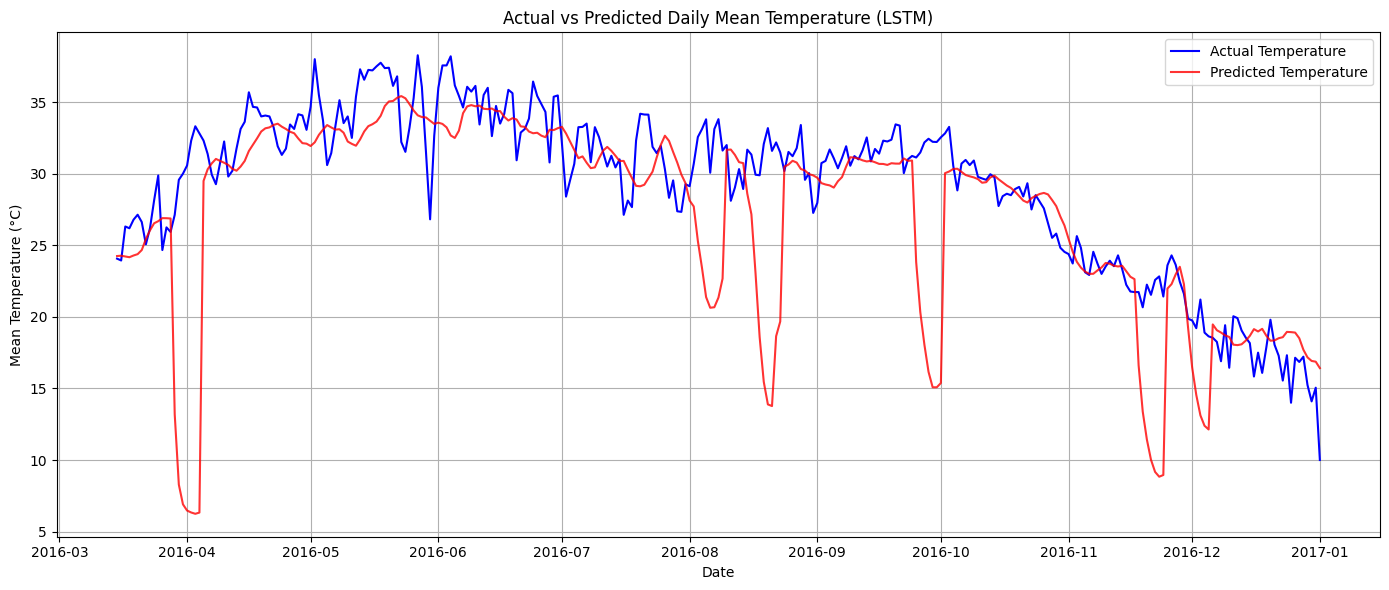

In [17]:
test_dates = df["date"].iloc[target_indices[test_mask]].reset_index(drop=True)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test_celsius,
    label="Actual Temperature",
    color="blue"
)

plt.plot(
    test_dates,
    y_pred_celsius,
    label="Predicted Temperature",
    color="red",
    alpha=0.8
)

plt.title("Actual vs Predicted Daily Mean Temperature (LSTM)")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Temperature_C": y_test_celsius,
    "Predicted_Temperature_C": y_pred_celsius
})

results["Absolute_Error_C"] = abs(
    results["Actual_Temperature_C"] -
    results["Predicted_Temperature_C"]
)

display(results.head(10))

,Date,Actual_Temperature_C,Predicted_Temperature_C,Absolute_Error_C
0,2016-03-15,24.066666,24.247623,0.180957
1,2016-03-16,23.937499,24.269985,0.332485
2,2016-03-17,26.312500,24.216845,2.095655
3,2016-03-18,26.187500,24.165182,2.022318
4,2016-03-19,26.785715,24.285272,2.500443
5,2016-03-20,27.133334,24.379982,2.753352
6,2016-03-21,26.625001,24.665281,1.959720
7,2016-03-22,25.062500,25.437630,0.375130
8,2016-03-23,26.199999,26.043044,0.156955
9,2016-03-24,28.133333,26.536279,1.597054


In [19]:
model.save("temperature_lstm_model.keras")

print("Trained LSTM model saved successfully.")

Trained LSTM model saved successfully.


In [20]:
from google.colab import files
files.download("temperature_lstm_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Step 1: Predict temperatures using the trained LSTM model
y_pred_scaled = model.predict(X_test, verbose=0)

# Step 2: Convert normalized values back to Celsius
temp_min = scaler.data_min_[0]
temp_max = scaler.data_max_[0]

y_actual = y_test * (temp_max - temp_min) + temp_min
y_predicted = (
    y_pred_scaled.flatten() * (temp_max - temp_min) + temp_min
)

# Step 3: Calculate MAE and RMSE
mae = mean_absolute_error(y_actual, y_predicted)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_predicted)
)

# Step 4: Display the results
print("LSTM Model Evaluation")
print("---------------------")
print(f"MAE  : {mae:.4f} °C")
print(f"RMSE : {rmse:.4f} °C")


LSTM Model Evaluation
---------------------
MAE  : 3.2786 °C
RMSE : 5.7911 °C


In [22]:

results = pd.DataFrame({
    "Actual Temperature (°C)": y_actual,
    "Predicted Temperature (°C)": y_predicted
})

results["Absolute Error (°C)"] = abs(
    results["Actual Temperature (°C)"]
    - results["Predicted Temperature (°C)"]
)

display(results.head(10))


,Actual Temperature (°C),Predicted Temperature (°C),Absolute Error (°C)
0,24.066666,24.247623,0.180957
1,23.937499,24.269985,0.332485
2,26.312500,24.216845,2.095655
3,26.187500,24.165182,2.022318
4,26.785715,24.285272,2.500443
5,27.133334,24.379982,2.753352
6,26.625001,24.665281,1.959720
7,25.062500,25.437630,0.375130
8,26.199999,26.043044,0.156955
9,28.133333,26.536279,1.597054


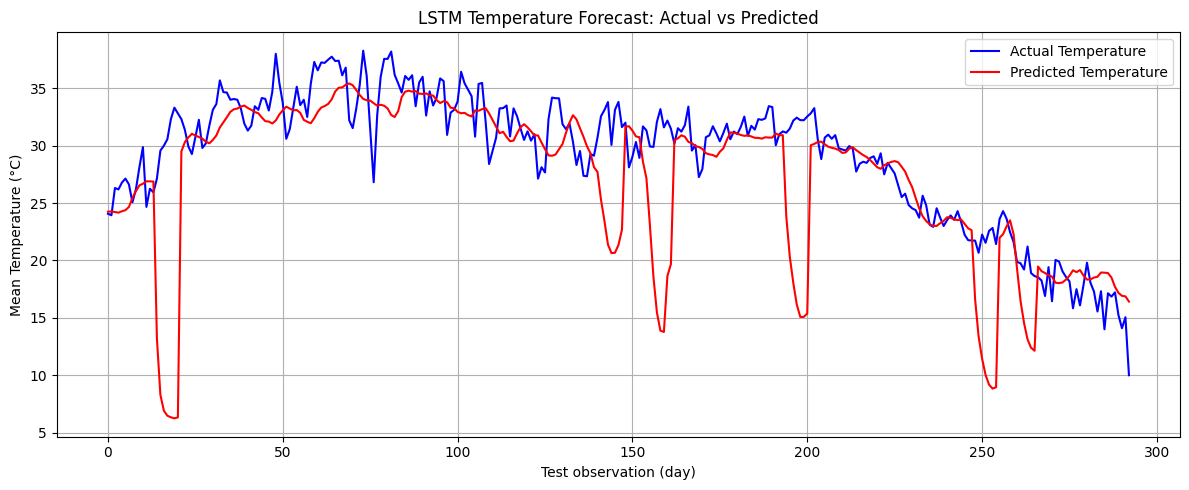

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(y_actual, label="Actual Temperature", color="blue")
plt.plot(y_predicted, label="Predicted Temperature", color="red")

plt.title("LSTM Temperature Forecast: Actual vs Predicted")
plt.xlabel("Test observation (day)")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


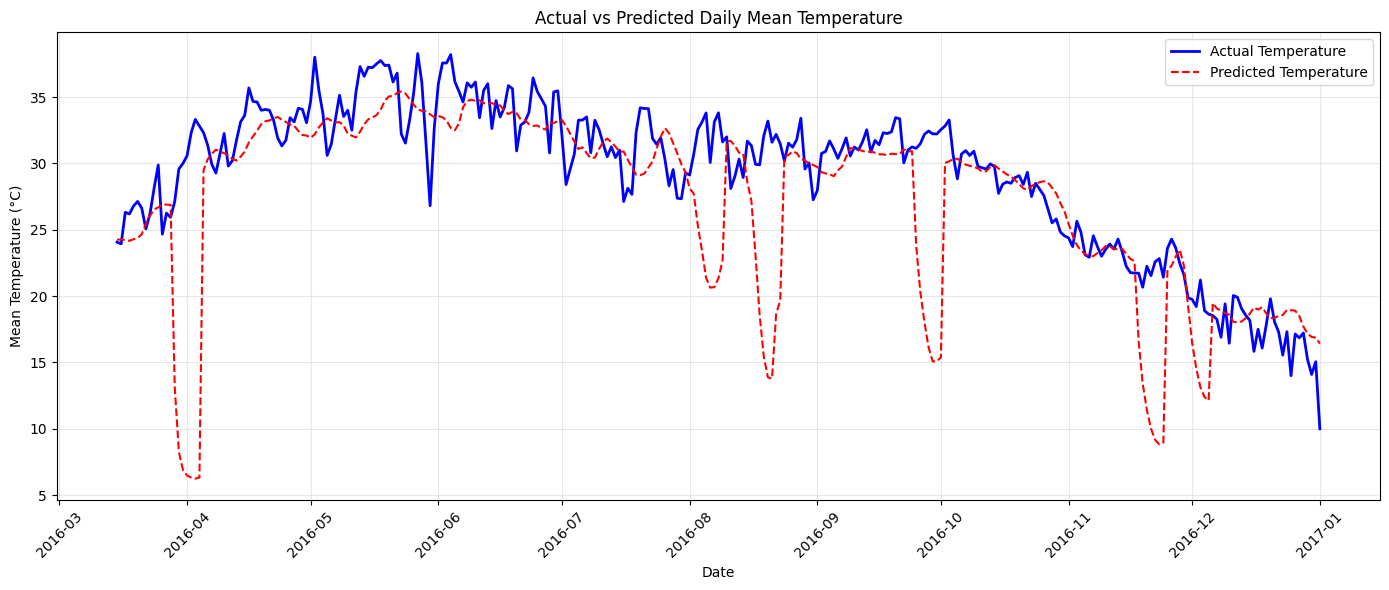

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predict on the held-out test sequences
y_pred_scaled = model.predict(X_test, verbose=0).flatten()

# Convert normalized values back to Celsius
temp_min = scaler.data_min_[0]
temp_max = scaler.data_max_[0]

y_actual = y_test * (temp_max - temp_min) + temp_min
y_predicted = y_pred_scaled * (temp_max - temp_min) + temp_min

# Get dates for the test predictions
test_dates = df["date"].iloc[target_indices[test_mask]].reset_index(drop=True)

# Plot actual and predicted temperature
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates, y_actual,
    label="Actual Temperature",
    color="blue",
    linewidth=2
)

plt.plot(
    test_dates, y_predicted,
    label="Predicted Temperature",
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted Daily Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


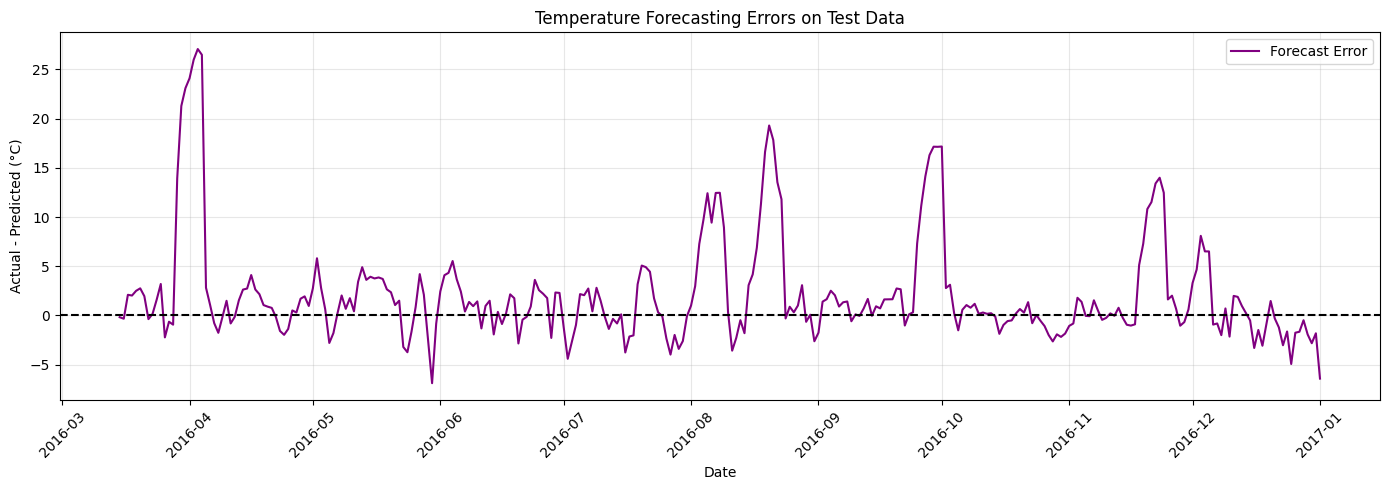

Mean error: 2.151 °C
Mean absolute error: 3.279 °C


In [25]:

# Positive error: actual temperature is higher than predicted
# Negative error: actual temperature is lower than predicted
errors = y_actual - y_predicted

plt.figure(figsize=(14, 5))

plt.plot(test_dates, errors, color="purple", label="Forecast Error")
plt.axhline(y=0, color="black", linestyle="--")

plt.title("Temperature Forecasting Errors on Test Data")
plt.xlabel("Date")
plt.ylabel("Actual - Predicted (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Mean error: {np.mean(errors):.3f} °C")
print(f"Mean absolute error: {np.mean(np.abs(errors)):.3f} °C")


In [26]:

# Create a table of predictions for unseen test observations
unseen_results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Temperature_C": y_actual,
    "Predicted_Temperature_C": y_predicted
})

unseen_results["Absolute_Error_C"] = np.abs(
    unseen_results["Actual_Temperature_C"]
    - unseen_results["Predicted_Temperature_C"]
)

print("Sample forecasts on unseen test data:")
display(unseen_results.head(15).round(3))

print("\nOverall unseen test performance:")
print(f"Test observations: {len(unseen_results)}")
print(
    f"MAE: {np.mean(unseen_results['Absolute_Error_C']):.3f} °C"
)
print(
    f"RMSE: {np.sqrt(np.mean(errors**2)):.3f} °C"
)


Sample forecasts on unseen test data:


,Date,Actual_Temperature_C,Predicted_Temperature_C,Absolute_Error_C
0,2016-03-15,24.067,24.248,0.181
1,2016-03-16,23.937,24.270,0.332
2,2016-03-17,26.313,24.217,2.096
3,2016-03-18,26.188,24.165,2.022
4,2016-03-19,26.786,24.285,2.500
5,2016-03-20,27.133,24.380,2.753
6,2016-03-21,26.625,24.665,1.960
7,2016-03-22,25.062,25.438,0.375
8,2016-03-23,26.200,26.043,0.157
9,2016-03-24,28.133,26.536,1.597



Overall unseen test performance:
Test observations: 293
MAE: 3.279 °C
RMSE: 5.791 °C


In [27]:

# Prepare the latest seven days of historical features
latest_data = df.sort_values("date").tail(sequence_length).copy()

# Transform with the scaler fitted during Task 3
latest_scaled = scaler.transform(latest_data[features])

# Reshape to (samples, time steps, features)
latest_sequence = latest_scaled.reshape(
    1, sequence_length, len(features)
)

# Predict next day's normalized mean temperature
next_temp_scaled = model.predict(
    latest_sequence, verbose=0
)[0, 0]

# Convert prediction back to Celsius
next_temp_celsius = (
    next_temp_scaled * (temp_max - temp_min) + temp_min
)

# Show forecast date
last_date = latest_data["date"].max()
forecast_date = last_date + pd.Timedelta(days=1)

print("Next-Day Temperature Forecast")
print("-----------------------------")
print("Last observed date:", last_date.date())
print("Forecast date:", forecast_date.date())
print(f"Predicted mean temperature: {next_temp_celsius:.2f} °C")


Next-Day Temperature Forecast
-----------------------------
Last observed date: 2017-01-01
Forecast date: 2017-01-02
Predicted mean temperature: 16.18 °C


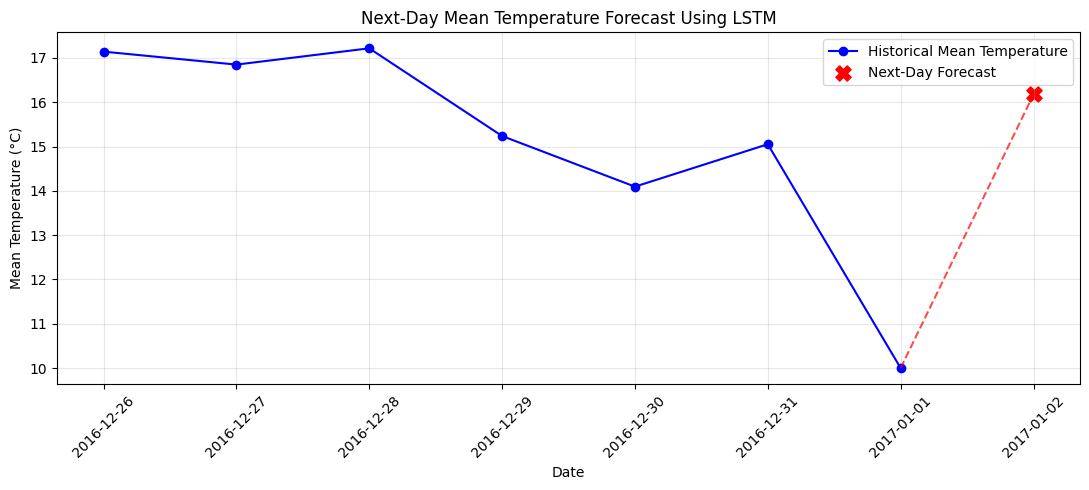

In [28]:

recent_dates = latest_data["date"]
recent_temps = latest_data["meantemp"]

plt.figure(figsize=(11, 5))

plt.plot(
    recent_dates,
    recent_temps,
    marker="o",
    color="blue",
    label="Historical Mean Temperature"
)

plt.scatter(
    [forecast_date],
    [next_temp_celsius],
    color="red",
    s=120,
    marker="X",
    label="Next-Day Forecast"
)

plt.plot(
    [recent_dates.iloc[-1], forecast_date],
    [recent_temps.iloc[-1], next_temp_celsius],
    linestyle="--",
    color="red",
    alpha=0.7
)

plt.title("Next-Day Mean Temperature Forecast Using LSTM")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [29]:
import numpy as np
import pandas as pd

# Select the latest 7 days of weather data
latest_data = df.sort_values("date").tail(7)

# Select the 4 input features
features = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

# Normalize using the scaler from Task 3
input_data = scaler.transform(latest_data[features])

# Reshape for LSTM: (samples, time steps, features)
X_input = input_data.reshape(1, 7, 4)

print("Input shape:", X_input.shape)
print(X_input)

Input shape: (1, 7, 4)
[[[0.34061135 0.72635135 0.20805804 0.80877094]
  [0.33165939 0.63994932 0.19741829 0.81660079]
  [0.34288969 0.64578437 0.08403188 0.76490806]
  [0.28238719 0.88006757 0.14211274 0.8072652 ]
  [0.24745269 0.90146396 0.14842886 0.83888575]
  [0.276718   0.86993243 0.17349597 0.78181818]
  [0.12227074 1.02364865 0.         0.77865613]]]


In [30]:
# Predict the next day's normalized temperature
predicted_scaled = model.predict(X_input, verbose=0)[0, 0]

# Convert normalized temperature back to Celsius
temp_min = scaler.data_min_[0]
temp_max = scaler.data_max_[0]

predicted_temp = (
    predicted_scaled * (temp_max - temp_min) + temp_min
)

print("Predicted next-day mean temperature:",
      round(float(predicted_temp), 2), "°C")

Predicted next-day mean temperature: 16.18 °C
